In [1]:
import pandas as pd

df = pd.read_csv("../data/Churn-Dataset.csv")

print(df.head())
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
import pandas as pd

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
print(df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

df = df.drop(columns=["customerID"], errors="ignore")

X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

float64
Missing TotalCharges: 11
Features shape: (7043, 19)
Target shape: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
print(y.isna().sum())
print(y.value_counts())

0
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (5634, 19)
Testing set: (1409, 19)


In [5]:
numeric_feature=X_train.select_dtypes(include=['number']).columns.tolist()
categorical_feature=X_train.select_dtypes(include=['object','bool','category','string']).columns.tolist()

print("Numerical features:", numeric_feature)
print("Categorical features:", categorical_feature)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
                        ("Impute",SimpleImputer(strategy='median')),
                        ('Scaler',StandardScaler())
]) 
categoric_pipeline = Pipeline([
                        ('Impute',SimpleImputer(strategy='most_frequent')),
                        ('Encoder',OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
                    ('num',numeric_pipeline,numeric_feature),
                    ('cat',categoric_pipeline,categorical_feature)
])



In [7]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_preprocessed.shape)
print("Processed testing shape:", X_test_preprocessed.shape)

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


In [8]:
print("Original feature count:", X_train.shape[1])
print("Processed feature count:", X_train_preprocessed.shape[1])

print("Training samples:", X_train_preprocessed.shape[0])
print("Testing samples:", X_test_preprocessed.shape[0])

Original feature count: 19
Processed feature count: 45
Training samples: 5634
Testing samples: 1409


In [9]:
from sklearn.linear_model import LogisticRegression

lr_model=Pipeline([
    ('preprocessor',preprocessor),
    ('model',LogisticRegression(max_iter=1000))
])

In [10]:
lr_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [11]:
predictions=lr_model.predict(X_test)

Accuracy:  0.8055358410220014

Classification Report: 
               precision    recall  f1-score   support

      Stayed       0.89      0.85      0.87      1091
     Churned       0.56      0.66      0.60       318

    accuracy                           0.81      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.82      0.81      0.81      1409



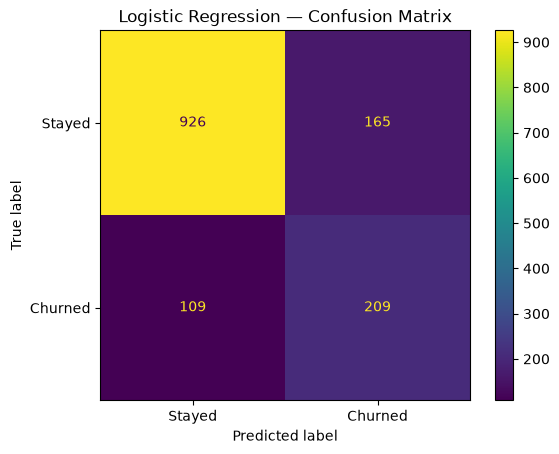

In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print('Accuracy: ',accuracy_score(predictions,y_test))
print("\nClassification Report: \n",classification_report(predictions,y_test,target_names=["Stayed", "Churned"]))

cm = confusion_matrix(predictions,y_test)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("Logistic Regression — Confusion Matrix")
plt.show()

In [13]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models={
    'Logistic Regression' : LogisticRegression(max_iter=1000),
    'Decision Tree' : DecisionTreeClassifier(max_depth=6,random_state=42),
    'Random Forest' : RandomForestClassifier(n_estimators=200,random_state=42)
}
result=[]


for name,classifier in models.items():
    model=Pipeline([
        ('preprocessor',clone(preprocessor)),
        ('model',classifier)
    ])
    model.fit(X_train, y_train)
    pred=model.predict(X_test)
    result.append({
        "Model" : name,
        "Accuracy" : accuracy_score(y_test,pred),
        "Precision_score" : precision_score(y_test,pred,zero_division=0),
        "Recall_score" : recall_score(y_test,pred,zero_division=0),
        "F1_score" : f1_score(y_test,pred,zero_division=0)
    })


result=pd.DataFrame(result)    
print(result)

                 Model  Accuracy  Precision_score  Recall_score  F1_score
0  Logistic Regression  0.805536         0.657233      0.558824  0.604046
1        Decision Tree  0.791341         0.634228      0.505348  0.562500
2        Random Forest  0.775727         0.600000      0.465241  0.524096


In [14]:
thresholds=[0.3,0.4,0.5,0.6]
predicted_proba = lr_model.predict_proba(X_test)[:,1]
for threshold in thresholds:
    threshold_pred = (predicted_proba>=threshold).astype(int)
    print("\nThreshold: ",threshold)
    print("Precision:", round(
        precision_score(y_test, threshold_pred, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_test, threshold_pred, zero_division=0), 3
    ))
    print("F1-score:", round(
        f1_score(y_test, threshold_pred, zero_division=0), 3
    ))


Threshold:  0.3
Precision: 0.519
Recall: 0.754
F1-score: 0.615

Threshold:  0.4
Precision: 0.569
Recall: 0.668
F1-score: 0.615

Threshold:  0.5
Precision: 0.657
Recall: 0.559
F1-score: 0.604

Threshold:  0.6
Precision: 0.718
Recall: 0.401
F1-score: 0.515


ROC-AUC Score: 0.8419


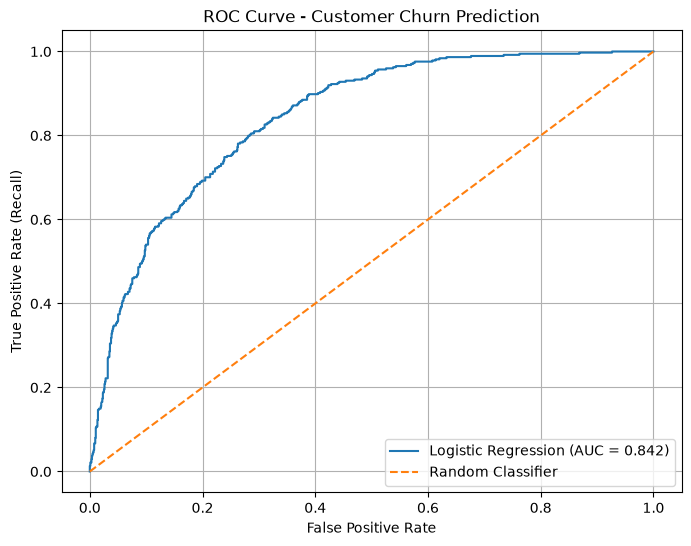

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr,tpr,threshold=roc_curve(y_test,predicted_proba)

roc_auc=roc_auc_score(y_test,predicted_proba)

print("ROC-AUC Score:", round(roc_auc, 4))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
feature_names=lr_model.named_steps['preprocessor'].get_feature_names_out()
coefficients=lr_model.named_steps['model'].coef_[0]

imp_feature=pd.DataFrame({
    'feature':feature_names,
    'Coefficient':coefficients
})
imp_feature['Absolute_Values'] = (imp_feature['Coefficient'].abs())
imp_feature = imp_feature.sort_values(by='Absolute_Values',ascending=False)
imp_feature.head()

,feature,Coefficient,Absolute_Values
1,num__tenure,-1.241319,1.241319
38,cat__Contract_Two year,-0.772261,0.772261
15,cat__InternetService_DSL,-0.652406,0.652406
16,cat__InternetService_Fiber optic,0.640026,0.640026
2,num__MonthlyCharges,-0.596392,0.596392
